### Generate source descriptions

#### 1. Extract source caption

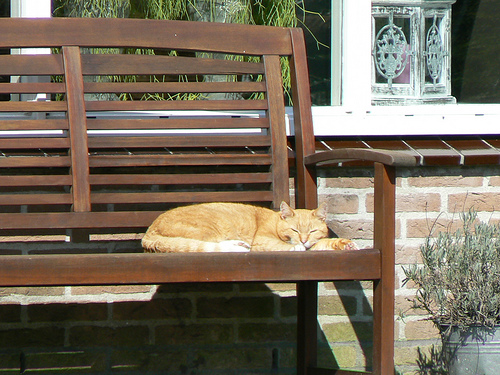

The image shows a wooden bench with a reddish-brown finish placed outdoors. A ginger cat is lying on the bench, stretched out comfortably and sleeping in the sunlight. The bench is positioned in front of a building with a brick wall and a partially visible window. Inside the window, there is a decorative item that appears to be a lantern or a similar object with intricate details. To the side of the bench, there is a potted plant with dry or sparse foliage. The sunlight is casting shadows, indicating that it is a sunny day.


In [ ]:
import os
import base64
from openai import OpenAI
from IPython.display import Image, display
os.environ["OPENAI_API_KEY"] = YOUR_API_KEY

client = OpenAI()

# Function to encode the image
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

# Path to your image
image_path = "./demo/original.jpg"

# Getting the Base64 string
base64_image = encode_image(image_path)

completion = client.chat.completions.create(
    model="gpt-4o",
    messages=[
        {
            "role": "system",
            "content": "You are a helpful assistant that helps users to extract visual characteristics from a given image.",
        },
        {
            "role": "user",
            "content": [
                { "type": "text", "text": "Describe what's in the image in detail. Do not include opinions or non-visual aspects. Make the descriptions easy and intuitive." },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{base64_image}",
                    },
                },
            ],
        }
    ],
)

source_caption = completion.choices[0].message.content
# Display the image in the notebook
display(Image(filename=image_path))

print(source_caption)

#### 2. Parse source caption into descriptions

In [13]:
from typing import List
from pydantic import BaseModel

in_context_samples = [{
                "role": "user", 
                "content": "The image features a large, dark-colored dog standing in a grassy field. The dog appears to be alert and attentive, possibly observing its surroundings. The grass is lush and green, providing a natural backdrop for the dog."
            },
            {
                "role": "assistant", 
                "content": """
                        ["A dog is large", "A dog is dark-colored", "A dog is standing", "A dog is standing on a grassy field", "A dog is alert", "A dog is attentive", "A dog is observing its surroundings", "A grass is lush", "A grass is green", "A grass is providing a natural backdrop"]
                    """ 
            },
            {
                "role": "user",
                "content": "Red haired girl in the image has visual features like curly hair, wearing a hat and blue pajamas and holding a cup of coffee, while a black haired woman is wearing black suit and writing down notes. They are both in a cafe, sitting around a round table"
            },
            {
                "role": "assistant",
                "content": """
                    ["Red haired girl has curly hair",
                    "Red haired girl is wearing a hat", 
                    "Red haired girl is wearing blue pajamas", 
                    "Red haired girl is holding a cup of coffee",
                    "Red haired girl is in a cafe",
                    "Red haired girl is sitting around a round table",
                    ]
                    """
            }
]

class Description(BaseModel):
    descriptions: List[str]
    
completion = client.beta.chat.completions.parse(
    model="gpt-4o",
    messages=[
        {"role": "system", "content": "You are a helpful assistant that extracts visual descriptions from a given text. Each visual description should include single visual characteristics of the image."},

    ] 
    + in_context_samples 
    + [
        {
            "role": "user",
            "content": source_caption,
        }
    ],
    response_format=Description,
)

source_desc = completion.choices[0].message.parsed.descriptions
print(source_desc)

['A bench is wooden', 'A bench has a reddish-brown finish', 'A bench is placed outdoors', 'A cat is ginger', 'A cat is lying on the bench', 'A cat is stretched out', 'A cat is sleeping', 'A cat is in sunlight', 'A building has a brick wall', 'A building has a partially visible window', 'A window has a decorative item inside', 'A decorative item appears to be a lantern', 'A decorative item has intricate details', 'A bench is positioned in front of a building', 'A potted plant is to the side of the bench', 'A potted plant has dry or sparse foliage', 'Sunlight is casting shadows', 'It is a sunny day']


#### 3. Extract target descriptions

In [12]:
in_context_samples = [
    {
        "role": "user",
        "content": "In order to make a person into a standing posture, what visual attributes of the image should be changed? Answer in the format of 'Standing person is ATTRIBUTE'."
    },
    {
        "role": "assistant", 
        "content": """
                [
                    "Standing person has straight legs", 
                    "Standing person is upright", 
                    "Standing person is on their feet", 
                    "Standing person is tall"
                ]
                """ 
    },
    {
        "role": "user",
        "content": "In order to make the shape round, what visual attributes of the image should be changed? Answer in the format of 'Round shape is ATTRIBUTE'."
    },
    {
        "role": "assistant",
        "content": """
                [
                    "Round shape is smooth",
                    "Round shape has curved edges",
                    "Round shape is circular",
                    "Round shape has no corners"
                ]
                """
    },
    {
        "role": "user",
        "content": "In order to add a bag to a person, what visual attributes of the image should be changed? Answer in the format of 'Person with bag is ATTRIBUTE'."
    },
    {
        "role": "assistant",
        "content": """
                [
                    "Person with bag has a strap over the shoulder",
                    "Person with bag is carrying an item",
                    "Person with bag has an object on their side",
                    "Person with bag has a bag visible near their hip"
                ]
                """
    }
]

target_text = "Add a bag"
completion = client.beta.chat.completions.parse(
    model="gpt-4o",
    messages=[
        {
            "role": "system", 
            "content": "You are a helpful text-generation assistant. Given a detailed textual description of an image, your goal is to parse it into specific visual attributes. If the visual attributes with similar meanings are repeated, only use one. For example, 'A dog is large' and 'A dog is big' are similar, so only use one."
        }
    ] 
    + in_context_samples 
    + [
        {
            "role": "user",
            "content": f"In order to {target_text.lower()}, what visual attributes should be present in the image of {source_caption}? Answer in the format of 'The OBJECT is ATTRIBUTE'. Replace OBJECT and ATTRIBUTE with appropriate words."
        }
    ],
    response_format=Description,
)

target_desc = completion.choices[0].message.parsed.descriptions
print(target_desc)


['The bag is placed on the bench', 'The bag is next to the cat', 'The bag is visible on the seat', 'The bag has handles or straps']


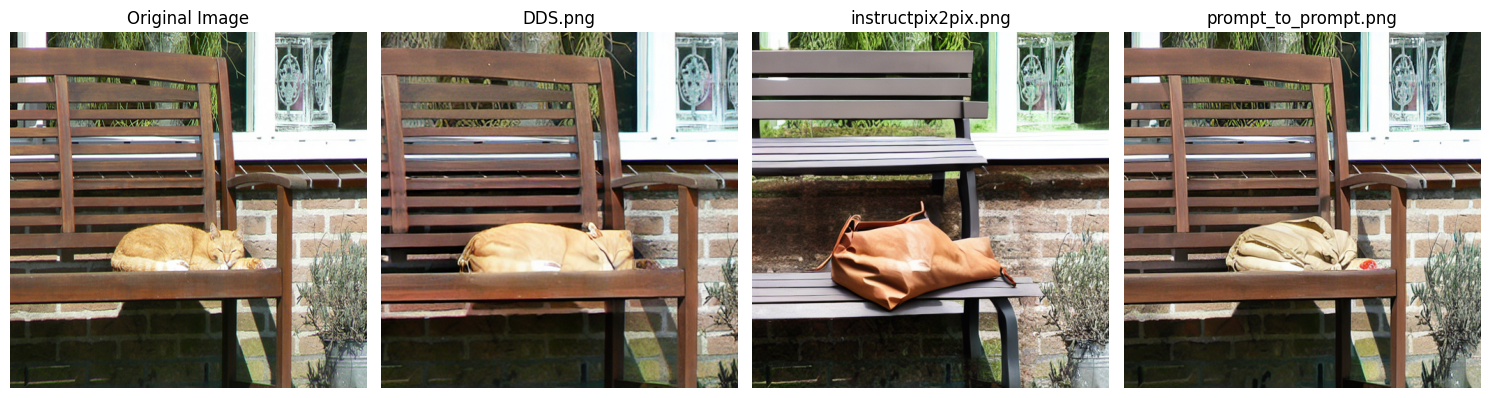

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

manip_path = ["./demo/DDS.png", "./demo/instructpix2pix.png", "./demo/prompt_to_prompt.png"]
fig, axes = plt.subplots(1, len(manip_path) + 1, figsize=(15, 5))

orig_img = Image.open(image_path).convert('RGB').resize((512, 512))
axes[0].imshow(orig_img)
axes[0].set_title("Original Image")
axes[0].axis('off')
for ax, img_path in zip(axes[1:], manip_path):
    img = Image.open(img_path).convert('RGB').resize((512, 512))
    ax.imshow(img)
    ax.set_title(img_path.split('/')[-1])
    ax.axis('off')

plt.tight_layout()
plt.show()

In [10]:
import torch
import numpy as np

from evaluation.eval_base import BaseScore, AugCLIP
from evaluation.eval_class import SegmentConsistency, DINOAttSim
import torchvision.transforms.functional as ttf
from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity as LPIPS

def compute_metrics(src_image, manip_image, lpips, sc_model, dinosim):
    """
    The metrics are all computed in the similarity concept.
    Ther larger the better
    """
    #! Segment Consistency
    sc_score = sc_model.seg_accuracy(src_image, manip_image).item()
    #! DINO
    dino_score = float(dinosim.compute(org_image=src_image, tgt_image=manip_image))
    #! L2 Sim
    l2_sim = -(torch.norm(ttf.to_tensor(src_image) - ttf.to_tensor(manip_image), p=2, dim=1) / ttf.to_tensor(manip_image).shape[1]).mean().item()
    #! LPIPS
    lpips_score = lpips(ttf.to_tensor(src_image).unsqueeze(0), ttf.to_tensor(manip_image).unsqueeze(0))
    lpips_score = 100 * lpips_score.item()

    #! CLIP variants
    all_scores = {
        "LPIPS": lpips_score,
        "L2": l2_sim,
        "DINO": dino_score,
        "SC": sc_score
    }
    return all_scores


def compute_augclip(augclip, src_img_feat, tgt_img_feat, src_dist, tgt_dist, src_weight, trg_weight, lmbd=100):
    
    X = torch.cat([src_dist, tgt_dist]).detach().cpu().numpy()
    y = np.array([1] * src_dist.shape[0] + [2] * tgt_dist.shape[0])
    
    weight = lmbd * np.concatenate([src_weight, trg_weight])
    augclip.svc_model.fit(X, y, sample_weight=weight)
    w = augclip.svc_model.coef_ # d dim
    b = augclip.svc_model.intercept_ # d dim
    y_train_pred = augclip.svc_model.predict(X)
    misclassified_samples = (y != y_train_pred).mean()
    
    check_numpy = lambda x: x.detach().cpu().numpy() if not isinstance(x, np.ndarray) else x
    reshape_1d = lambda x: x.reshape(-1) if len(x.shape) > 1 else x
    check_torch = lambda x: torch.Tensor(x).to("cuda:0").half()
    src_img_feat, tgt_img_feat, w, b = map(reshape_1d, map(check_numpy, [src_img_feat, tgt_img_feat, w, b]))
    
    w_norm = np.linalg.norm(w)
    v = -(src_img_feat @ w.T + b) / (w_norm ** 2) * w
    src_img_feat, tgt_img_feat, v = map(check_torch, [src_img_feat, tgt_img_feat, v])
    score = (src_img_feat + v) @ (tgt_img_feat).T
    return v, score, misclassified_samples

In [ ]:
device = "cuda:0"
vl_model = "Vit"

augclip = AugCLIP(device, vl_model, penalty="l2")
base = BaseScore(device, vl_model)

from pprint import pprint
device = "cuda:0"
vl_model = "ViT-B/16"


Pretrained weights found at ./evaluation/dino/dino_deitsmall8_pretrain.pth and loaded with msg: <All keys matched successfully>
{'DINO': 0.8826088309288025,
 'L2': -0.00955352932214737,
 'LPIPS': 39.44947421550751,
 'SC': 46.82044982910156}


In [18]:
from torch.nn import functional as F
src_img_feat = base.get_image_embeddings([orig_img])


tgt_img_feat = base.get_image_embeddings([manip_image])
src_text = "A cat on a bench"
tgt_text = "Add a bag"
src_text_feat, tgt_text_feat = base.get_text_embeddings([src_text]), base.get_text_embeddings([tgt_text])        
src_desc_feat, tgt_desc_feat = base.get_text_embeddings(source_desc), base.get_text_embeddings(target_desc)

srcs = torch.cat([src_img_feat, src_desc_feat], dim=0)
src_dist = F.normalize(srcs, p=2, dim=-1)

scores = {}
for manip in manip_path:
    manip_image = Image.open(manip).convert('RGB').resize((512, 512))
    tgts = torch.cat([tgt_text_feat, tgt_desc_feat], dim=0)
    tgt_dist = F.normalize(tgts, p=2, dim=-1)
    src_weight, trg_weight = augclip.get_rel1_weight(src_dist - src_text_feat, tgt_dist - src_text_feat)

    v, score, miss = compute_augclip(augclip, src_img_feat, tgt_img_feat, src_dist, tgt_dist, src_weight, trg_weight, lmbd=100)
    augclip_score = score.item()
    clipscore = augclip.cs(tgt_img_feat - src_img_feat, tgt_text_feat - src_text_feat).item()
    scores[manip.split("/")[-1]] = {
        "AugCLIP": augclip_score,
        "CLIP": clipscore
    }
pprint(scores)

{'DDS.png': {'AugCLIP': 0.80615234375, 'CLIP': 0.11669921875},
 'instructpix2pix.png': {'AugCLIP': 0.810546875, 'CLIP': 0.11669921875},
 'prompt_to_prompt.png': {'AugCLIP': 0.82470703125, 'CLIP': 0.11669921875}}


### Test Other Evaluation Metrics

In [19]:
bisenet_path = "./evaluation/segment_consistency/model_final_v2_coco.pth"
dino_path = './evaluation/dino/dino_deitsmall8_pretrain.pth'

lpips = LPIPS(net_type='alex', reduction='mean')
sc_model = SegmentConsistency(bisenet_path, device)
dinosim = DINOAttSim(device, dino_path)

manip_image = Image.open(manip_path[0]).convert('RGB').resize((512, 512))
source_image = Image.open(image_path).convert('RGB').resize((512, 512))

tgt_img_feat = base.get_image_embeddings([manip_image])
other_scores = compute_metrics(orig_img, manip_image, lpips, sc_model, dinosim)
pprint(other_scores)

/home/server08/miniconda3/envs/augclip_eval/lib/python3.8/site-packages/torchmetrics/functional/image/lpips.py:325: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.load_s

Pretrained weights found at ./evaluation/dino/dino_deitsmall8_pretrain.pth and loaded with msg: <All keys matched successfully>
{'DINO': 0.8826088309288025,
 'L2': -0.00955352932214737,
 'LPIPS': 39.44947421550751,
 'SC': 46.82044982910156}
